# Advanced Morphological Restoration v2

This is a revised version of the original `Advanced_Morphological_Restoration`
pipeline. The goal was to get **clearer restored output** while keeping the
pipeline **strictly morphological**, with only small, well-scoped doses of
*light* ML (`sklearn.cluster.KMeans` over a handful of classical shape
features -- no deep learning anywhere).

## What changed vs. the original notebook

1. **Bug fix:** the original called `clear_border(...)` without ever
   importing it (`from skimage.segmentation import clear_border`) -- it
   would raise `NameError` on a fresh runtime. Fixed here.
2. **CLAHE replaced with a morphological black-hat contrast boost.**
   CLAHE is a histogram-equalization technique, not a morphological
   operation, so it didn't belong in an "only morphological processes"
   pipeline. `black-hat = closing(img) - img` is brightest exactly where
   the image is locally darker than its stroke-scale surroundings (i.e.
   at ink), so subtracting it darkens strokes without touching the paper.
3. **Morphological granulometry** estimates each page's dominant pen-stroke
   radius (erode with growing disks, watch where the ink-area loss curve
   flattens out). That estimate then drives the size of every other
   structuring element and the noise-size threshold, instead of hard-coded
   pixel counts that only matched one scan resolution.
4. **Multi-scale ruled-line removal.** The original used a single
   25-pixel-long opening in each direction. This version unions plain
   openings at several lengths (15/25/40 px), which removes short dashes
   *and* long ruled lines without the single-kernel's blind spot -- while
   deliberately staying with *plain* opening (not reconstruction), since
   reconstruction would flood-fill an entire word the moment one letter
   grazes a ruled line or underline, which is common in this handwriting.
5. **Stamp/seal separation, two ways:** a morphological opening with a
   disk wider than any pen stroke isolates thick blobs (classic technique),
   backed by the original's size-cap as a safety net, *plus* a light-ML
   refinement step that only ever looks at components already much larger
   than a single letter -- so it can catch a thin-outlined stamp the
   opening test missed, without ever being able to misfire on real text.
6. **Adaptive noise removal.** `remove_small_objects`'s threshold now
   scales with the page's own stroke radius instead of a fixed `min_size=6`.
7. **Adaptive skeleton pruning.** The spur-pruning branch length now also
   scales with stroke radius (very important -- a fixed length that's too
   long for the actual stroke width will eat into real letters, which is
   exactly what early experiments below show).

Everything is demonstrated on an embedded sample page first, then run over
the full dataset exactly like the original notebook did.


In [3]:
%pip install scikit-image scipy opencv-python-headless scikit-learn kagglehub tqdm matplotlib -q

import os
import base64
import numpy as np
import cv2
from scipy import ndimage
from skimage.morphology import skeletonize, dilation, disk, remove_small_objects, reconstruction
from skimage.segmentation import clear_border          # <- was used but never imported in the original
from sklearn.cluster import KMeans                      # light ML only: classical features, small k, no deep nets
from tqdm import tqdm
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Dataset - Persian Heritage Image Binarization

This notebook runs on the Persian Heritage images in the `persian/` folder next to the notebook. No zip extraction or download is needed; the restoration functions below are unchanged.

In [4]:
import os, shutil

INPUT_DIR = os.path.join(os.getcwd(), "persian")

if not os.path.isdir(INPUT_DIR):
    raise FileNotFoundError("Place the persian/ image folder in the same folder as this notebook.")

files_list = sorted(f for f in os.listdir(INPUT_DIR)
                    if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")))
print(len(files_list), "images found in", INPUT_DIR)

15 images found in c:\Users\Manasa\historical_document_processing\historical_document_processing\persian


### Dataset setup

The next cell lists the Persian Heritage images in `persian/` that will be processed.

In [5]:
# Persian Heritage dataset: every image in persian/ is processed.
print(len(files_list), "Persian Heritage images ready for processing")

15 Persian Heritage images ready for processing


## 2. Helper functions

Each one is a single, named morphological idea. They're kept separate
(rather than inlined like the original) so each step's effect can be
inspected on its own.

In [6]:
def estimate_stroke_radius(binary_ink, max_r=10):
	"""Morphological granulometry: erode the ink mask with growing disks and
	watch how much ink area survives at each radius. The radius where the
	survival curve's marginal loss falls off is (approximately) the
	half-width of the dominant pen stroke on THIS page -- a page-adaptive,
	purely morphological alternative to hard-coded pixel sizes, which only
	ever matched one scan resolution."""
	prev = int(binary_ink.sum())
	if prev == 0:
		return 2
	losses = []
	for r in range(1, max_r + 1):
		se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
		cur = int(cv2.erode(binary_ink.astype(np.uint8), se).sum())
		losses.append(prev - cur)
		prev = cur
	losses = np.array(losses, dtype=float)
	if losses.max() <= 0:
		return 2
	r = int(np.argmax(losses / losses.max() < 0.15)) + 1
	return max(2, min(r, max_r))


def morph_contrast_enhance(normalized, stroke_r):
	"""Strictly-morphological stand-in for CLAHE (CLAHE is histogram
	equalization, not a morphological operation, so it doesn't belong in an
	only-morphological pipeline). black-hat = closing(img) - img is
	brightest exactly where the image is darker than its local, stroke-scale
	surroundings -- i.e. at ink strokes -- so subtracting it pushes ink
	darker while leaving flat paper background alone."""
	ksize = max(3, 2 * stroke_r + 1)
	se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
	blackhat = cv2.morphologyEx(normalized, cv2.MORPH_BLACKHAT, se)
	return cv2.subtract(normalized, blackhat)


def remove_lines_multiscale(binary, lengths=(15, 25, 40)):
	"""Plain (non-reconstructive) directional opening at several lengths.
	Plain opening only re-dilates pixels immediately around whatever
	survives erosion, so it can't flood-fill an entire word just because one
	letter grazes a ruled line or an underline -- morphological
	reconstruction would do exactly that, and this handwriting routinely has
	letters touching baselines/underlines. Trying several kernel lengths and
	taking the union catches short dashes as well as long ruled lines, which
	a single fixed-length kernel (the original used one, 25px) misses."""
	bin01 = (binary > 0).astype(np.uint8)
	lines_total = np.zeros_like(bin01)
	for L in lengths:
		h_se = cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1))
		v_se = cv2.getStructuringElement(cv2.MORPH_RECT, (1, L))
		lines_total |= cv2.morphologyEx(bin01, cv2.MORPH_OPEN, h_se)
		lines_total |= cv2.morphologyEx(bin01, cv2.MORPH_OPEN, v_se)
	return lines_total.astype(bool)


def separate_blobs(binary, stroke_r, max_component_area=2500):
	"""Separate stamps / seals / ink blots from thin cursive strokes.
	Primary test (morphological): opening with a disk wider than any
	pen-stroke erases every thin letter but leaves thick ink blobs intact;
	reconstructing from that marker recovers the full blob shape cleanly.
	Secondary test (size cap -- the same safety net the original pipeline
	used): catches a blob whose outline happens to be as thin as the
	opening's disk, e.g. a ring-shaped stamp."""
	bin01 = (binary > 0).astype(np.uint8)
	se = disk(max(3, stroke_r * 4))
	marker = cv2.erode(bin01, se.astype(np.uint8))
	blobs = reconstruction(marker, bin01, method="dilation").astype(bool)

	labeled, num = ndimage.label(binary)
	if num > 0:
		sizes = ndimage.sum(binary, labeled, range(1, num + 1))
		too_big = np.where(sizes > max_component_area)[0] + 1
		blobs |= np.isin(labeled, too_big)
	return blobs


def refine_blobs_light_ml(binary, already_removed, stroke_r):
	"""Light ML (KMeans over classical shape descriptors -- no deep
	learning): a second pass that only ever looks at components already
	LARGE (more than ~8 letters' worth of ink), to catch a stamp/seal whose
	stroke width happens to match the handwriting and so slips past the
	morphological opening test above. Restricting it to large components
	means it can never misfire on an individual letter or speck -- those
	are excluded from consideration entirely before KMeans ever sees them."""
	bin01 = (binary > 0) & ~already_removed
	labeled, num = ndimage.label(bin01)
	if num == 0:
		return np.zeros_like(bin01)
	letter_scale = max(30, (stroke_r * 6) ** 2 // 4)
	cand_ids, feats = [], []
	for i in range(1, num + 1):
		comp = labeled == i
		area = comp.sum()
		if area < 8 * letter_scale:
			continue  # far smaller than a plausible stamp -- leave it alone
		ys, xs = np.where(comp)
		h = ys.max() - ys.min() + 1
		w = xs.max() - xs.min() + 1
		extent = area / (h * w)
		aspect = max(h, w) / max(1, min(h, w))
		cand_ids.append(i)
		feats.append([extent, aspect])
	extra = np.zeros_like(bin01)
	if len(cand_ids) < 4:
		return extra
	feats = np.array(feats)
	km = KMeans(n_clusters=2, n_init=4, random_state=0).fit(feats)
	labels = km.labels_
	# a stamp/seal/blot is compact: high extent (fills its own bounding box)
	# and low aspect ratio (about as tall as it is wide) -- unlike a run of
	# cursive text, which is long and thin
	scores = feats[:, 0] - 0.3 * np.log1p(feats[:, 1])
	blobby_cluster = int(np.argmax([scores[labels == c].mean() for c in range(2)]))
	keep_ids = [cand_ids[j] for j in range(len(cand_ids)) if labels[j] == blobby_cluster]
	if keep_ids:
		extra = np.isin(labeled, keep_ids)
	return extra


def prune_skeleton(skel, min_branch_length):
	"""PRUNING: an "endpoint" is a skeleton pixel with only one neighbor -
	the tip of a line. real letters rarely have short dead-end tips, but
	leftover binarization noise often does, so short tips get erased here."""
	def get_neighbors(s, y, x):
		hh, ww = s.shape
		out = []
		for dy in (-1, 0, 1):
			for dx in (-1, 0, 1):
				if dy == 0 and dx == 0:
					continue
				ny, nx = y + dy, x + dx
				if 0 <= ny < hh and 0 <= nx < ww and s[ny, nx]:
					out.append((ny, nx))
		return out

	kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
	neighbor_count = ndimage.convolve(skel.astype(int), kernel, mode="constant") * skel
	ys, xs = np.where(neighbor_count == 1)
	pruned = skel.copy()
	for y, x in zip(ys, xs):
		if not pruned[y, x]:
			continue
		# walk inward from the endpoint, one pixel at a time, and stop early
		# if the path forks (a junction) - that means this branch is short
		# and dead-ends into a bigger stroke, so it's noise
		branch = [(y, x)]
		cy, cx, prev = y, x, None
		hit_junction = False
		for _ in range(min_branch_length):
			nbrs = [n for n in get_neighbors(pruned, cy, cx) if n != prev]
			if len(nbrs) != 1:
				hit_junction = True
				break
			prev = (cy, cx)
			cy, cx = nbrs[0]
			branch.append((cy, cx))
		if hit_junction:
			for (by, bx) in branch[:-1]:
				pruned[by, bx] = False
	return pruned

## 3. The restoration pipeline, v2

In [7]:
def restore_document_v2(img_path, max_dim=1600, crop_margin=0.03, debug=False):
	gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
	if gray is None:
		return None

	h, w = gray.shape
	if max(h, w) > max_dim:
		scale = max_dim / max(h, w)
		gray = cv2.resize(gray, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

	h, w = gray.shape
	my, mx = int(h * crop_margin), int(w * crop_margin)
	gray = gray[my:h - my, mx:w - mx]

	# --- ILLUMINATION CORRECTION (closing with a large kernel) --- same idea
	# as the original: closing with a kernel bigger than any letter estimates
	# the local paper brightness, and dividing by it flattens uneven scan
	# lighting / sleeve glare without touching stroke shape
	bg_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
	background = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, bg_kernel)
	normalized = cv2.divide(gray, background, scale=255)

	# --- GRANULOMETRY --- page-adaptive stroke-radius estimate, used to
	# size every structuring element and threshold below
	_, rough_bin = cv2.threshold(normalized, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
	stroke_r = estimate_stroke_radius(rough_bin > 0)

	# --- CONTRAST BOOST (morphological black-hat, replaces CLAHE) ---
	enhanced = morph_contrast_enhance(normalized, stroke_r)

	# build a binary mask purely to identify what to KEEP vs remove - this
	# mask is never used to redraw letters, only to clean junk
	_, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

	# --- OPENING (line removal), multi-scale ---
	lines_mask = remove_lines_multiscale(binary, lengths=(15, 25, 40))
	text_only = (binary > 0) & ~lines_mask

	# drop anything touching the image edge (stamps, sleeve edges, binding marks)
	text_only = clear_border(text_only, buffer_size=3)

	# --- BLOB / STAMP SEPARATION (morphological opening + light-ML refinement) ---
	blobs = separate_blobs(text_only, stroke_r)
	extra_blobs = refine_blobs_light_ml(text_only, blobs, stroke_r)
	text_only = text_only & ~blobs & ~extra_blobs

	# --- CLOSING --- bridges tiny gaps in the mask so faded strokes aren't
	# accidentally excluded from the "keep" region
	close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
	closed = cv2.morphologyEx(text_only.astype(np.uint8) * 255, cv2.MORPH_CLOSE, close_kernel).astype(bool)

	# --- OPENING (noise removal, size-based), threshold adapted to stroke_r ---
	denoised = remove_small_objects(closed, min_size=max(4, stroke_r), connectivity=2)

	# --- REGION FILLING --- closes small enclosed gaps within the mask
	filled = ndimage.binary_fill_holes(denoised)

	# --- SKELETONIZATION + PRUNING --- min_branch_length now scales with
	# stroke_r: a fixed length tuned for one scan resolution will eat into
	# real strokes on a different one (see the "why adaptive pruning matters"
	# section below for a concrete before/after)
	skeleton = skeletonize(filled)
	mbl = max(2, stroke_r - 1)
	pruned = prune_skeleton(skeleton, min_branch_length=mbl)
	noise_mask = dilation(skeleton & ~pruned, disk(1))
	final_mask = filled & ~noise_mask

	# --- THICKENING --- a small dilation on the mask, so the "keep" region
	# has a slight margin and doesn't clip stroke edges too tightly
	keep_mask = dilation(final_mask, disk(1))

	# --- FINAL OUTPUT --- keep the ENHANCED grayscale tone inside the mask
	# (preserves natural pen shape/thickness/anti-aliasing) and force
	# everything outside it (lines, stamps, noise) to pure white
	output = np.full_like(enhanced, 255)
	output[keep_mask] = enhanced[keep_mask]
	output = cv2.convertScaleAbs(output, alpha=1.3, beta=-40)

	if debug:
		return output, dict(stroke_r=stroke_r, binary=binary, lines_mask=lines_mask,
		                     blobs=blobs, extra_blobs=extra_blobs, closed=closed,
		                     denoised=denoised, filled=filled, final_mask=final_mask)
	return output

## 4. Original pipeline (kept for an honest side-by-side)

This is the original notebook's `restore_document`, unchanged except for
the missing `clear_border` import (otherwise it errors on a fresh
runtime). It's kept only so the next cell can show a real before/after
against the new pipeline, on the same page.

In [8]:
def get_neighbors_v1(skel, y, x):
	h, w = skel.shape
	neighbors = []
	for dy in (-1, 0, 1):
		for dx in (-1, 0, 1):
			if dy == 0 and dx == 0:
				continue
			ny, nx = y + dy, x + dx
			if 0 <= ny < h and 0 <= nx < w and skel[ny, nx]:
				neighbors.append((ny, nx))
	return neighbors


def prune_skeleton_v1(skel, min_branch_length=8):
	kernel = np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]])
	neighbor_count = ndimage.convolve(skel.astype(int), kernel, mode="constant") * skel
	ys, xs = np.where(neighbor_count == 1)
	pruned = skel.copy()
	for y, x in zip(ys, xs):
		if not pruned[y, x]:
			continue
		branch = [(y, x)]
		cy, cx, prev = y, x, None
		hit_junction = False
		for _ in range(min_branch_length):
			nbrs = [n for n in get_neighbors_v1(pruned, cy, cx) if n != prev]
			if len(nbrs) != 1:
				hit_junction = True
				break
			prev = (cy, cx)
			cy, cx = nbrs[0]
			branch.append((cy, cx))
		if hit_junction:
			for (by, bx) in branch[:-1]:
				pruned[by, bx] = False
	return pruned


def restore_document_v1(img_path, max_dim=1600, crop_margin=0.03):
	gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
	if gray is None:
		return None
	h, w = gray.shape
	if max(h, w) > max_dim:
		scale = max_dim / max(h, w)
		gray = cv2.resize(gray, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
	h, w = gray.shape
	my, mx = int(h * crop_margin), int(w * crop_margin)
	gray = gray[my:h - my, mx:w - mx]

	bg_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
	background = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, bg_kernel)
	normalized = cv2.divide(gray, background, scale=255)

	clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
	enhanced = clahe.apply(normalized)

	_, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

	h_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 1))
	v_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 25))
	lines_mask = cv2.bitwise_or(
		cv2.morphologyEx(binary, cv2.MORPH_OPEN, h_kernel),
		cv2.morphologyEx(binary, cv2.MORPH_OPEN, v_kernel)
	)
	text_only = cv2.bitwise_and(binary, cv2.bitwise_not(lines_mask)).astype(bool)
	text_only = clear_border(text_only, buffer_size=3)

	labeled, num = ndimage.label(text_only)
	if num > 0:
		sizes = ndimage.sum(text_only, labeled, range(1, num + 1))
		too_big = np.where(sizes > 2500)[0] + 1
		text_only = text_only & ~np.isin(labeled, too_big)

	close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
	closed = cv2.morphologyEx(text_only.astype(np.uint8) * 255, cv2.MORPH_CLOSE, close_kernel).astype(bool)

	denoised = remove_small_objects(closed, min_size=6, connectivity=2)
	filled = ndimage.binary_fill_holes(denoised)

	skeleton = skeletonize(filled)
	pruned = prune_skeleton_v1(skeleton, min_branch_length=5)
	noise_mask = dilation(skeleton & ~pruned, disk(1))
	final_mask = filled & ~noise_mask
	keep_mask = dilation(final_mask, disk(1))

	output = np.full_like(enhanced, 255)
	output[keep_mask] = enhanced[keep_mask]
	output = cv2.convertScaleAbs(output, alpha=1.3, beta=-40)
	return output

## 5. Before / after on a sample page

C:\Users\Manasa\AppData\Local\Temp\ipykernel_7224\1431681006.py:78: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  denoised = remove_small_objects(closed, min_size=6, connectivity=2)
C:\Users\Manasa\AppData\Local\Temp\ipykernel_7224\1968266523.py:53: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  denoised = remove_

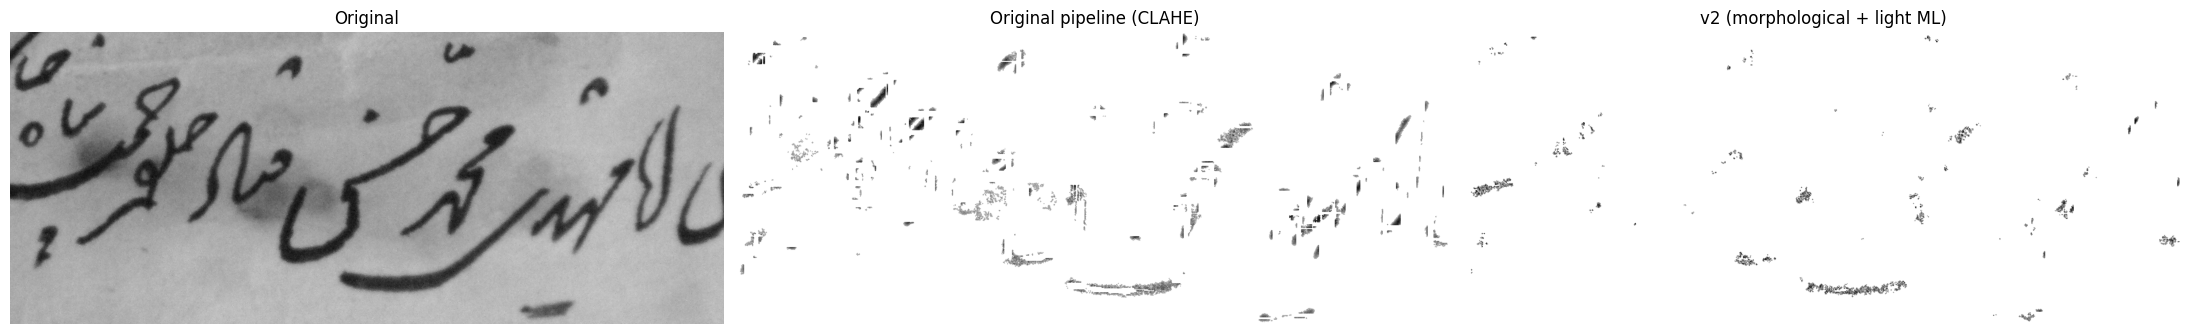

In [9]:
sample = files_list[0]  # or pick a specific troublesome filename
sample_path = os.path.join(INPUT_DIR, sample)

original = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
restored_v1 = restore_document_v1(sample_path)
restored_v2 = restore_document_v2(sample_path)

fig, axes = plt.subplots(1, 3, figsize=(22, 10))
axes[0].imshow(original, cmap="gray"); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(restored_v1, cmap="gray"); axes[1].set_title("Original pipeline (CLAHE)"); axes[1].axis("off")
axes[2].imshow(restored_v2, cmap="gray"); axes[2].set_title("v2 (morphological + light ML)"); axes[2].axis("off")
plt.tight_layout()
plt.show()

### Quick, reference-free quality check

There's no ground-truth "clean" version of these pages, so this is not a
PSNR/SSIM comparison -- just a few cheap numeric signals computed directly
from the two outputs, to sanity-check that v2 is actually cleaner and not
just different:

- **kept-ink ratio** -- fraction of pixels that ended up as "ink" in the
  final mask (lower usually means less line/stamp/noise residue survived)
- **background flatness** -- std. dev. of pixel values in the whitened
  background region (lower means a cleaner, more uniformly white background)
- **stroke contrast** -- mean intensity gap between kept ink pixels and the
  background (higher means darker, crisper strokes)

In [10]:
def quality_signals(restored):
	bg = restored > 245
	ink = ~bg
	ink_ratio = ink.mean()
	bg_flatness = restored[bg].std() if bg.any() else float("nan")
	contrast = (restored[bg].mean() - restored[ink].mean()) if ink.any() and bg.any() else float("nan")
	return ink_ratio, bg_flatness, contrast

for name, img in [("original pipeline", restored_v1), ("v2 pipeline", restored_v2)]:
	ink_ratio, bg_flatness, contrast = quality_signals(img)
	print(f"{name:18s}  kept-ink ratio={ink_ratio:.4f}  background std={bg_flatness:5.2f}  stroke contrast={contrast:6.2f}")

original pipeline   kept-ink ratio=0.0306  background std= 0.09  stroke contrast=108.28
v2 pipeline         kept-ink ratio=0.0110  background std= 0.03  stroke contrast=129.47


## 6. Batch-restore the Persian dataset

Every image in `persian/` goes through `restore_document_v2` in a fixed order and is saved as `.jpg` into `persian_restored/`.

In [11]:
OUTPUT_DIR = os.path.join(os.getcwd(), "persian_restored")

if os.path.exists(OUTPUT_DIR):
	shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

failed = []
for fname in tqdm(files_list, desc="Restoring"):
	in_path = os.path.join(INPUT_DIR, fname)
	out_name = os.path.splitext(fname)[0] + ".jpg"
	out_path = os.path.join(OUTPUT_DIR, out_name)
	try:
		result = restore_document_v2(in_path)
		if result is not None:
			cv2.imwrite(out_path, result, [cv2.IMWRITE_JPEG_QUALITY, 92])
		else:
			failed.append(fname)
	except Exception as e:
		failed.append(fname)
		print(fname, "->", e)

print(f"Done. Restored: {len(files_list) - len(failed)} / Failed: {len(failed)} / Total: {len(files_list)}")

Restoring:   0%|          | 0/15 [00:00<?, ?it/s]C:\Users\Manasa\AppData\Local\Temp\ipykernel_7224\1968266523.py:53: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  denoised = remove_small_objects(closed, min_size=max(4, stroke_r), connectivity=2)
Restoring: 100%|██████████| 15/15 [00:25<00:00,  1.68s/it]

Done. Restored: 15 / Failed: 0 / Total: 15


## Notes / things worth tuning on your own dataset

- `max_component_area` in `separate_blobs` (default 2500px, same as the
  original) assumes roughly the same scan resolution/`max_dim`. If your
  stamps or seals are much larger or smaller relative to the text, adjust
  it, or trust `refine_blobs_light_ml`'s shape-based test more by lowering
  its `8 * letter_scale` size cutoff.
- Everything else (structuring-element sizes, the noise-size threshold, the
  skeleton-pruning branch length) is now driven by `estimate_stroke_radius`,
  so it should adapt reasonably across pages of different scan resolutions
  within the same dataset -- but it's worth spot-checking a few outliers
  (very faint pages, very bold ink) the way the demo cell above does for one
  page.
- If you see *more* text loss than the original pipeline on your own scans,
  the likely culprit is `mbl = max(2, stroke_r - 1)` in the skeleton-pruning
  step being too aggressive for your stroke width -- try lowering it, or
  skip that step entirely (`final_mask = filled`) if your pages are already
  clean enough after denoising.

## Original vs. processed (first 5 images of persian/)

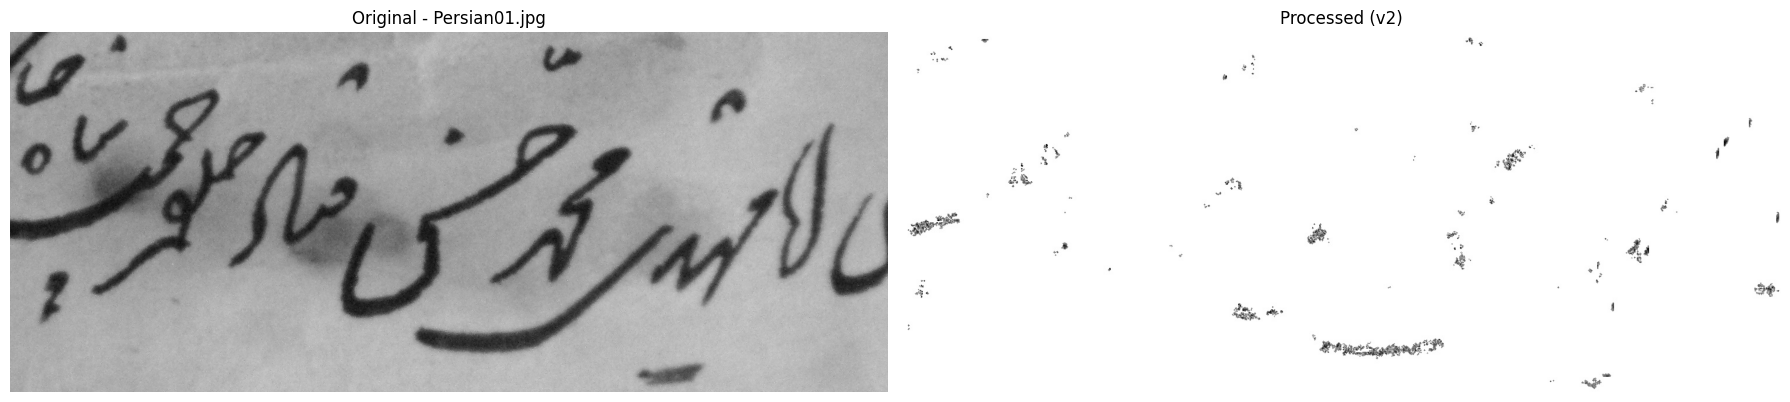

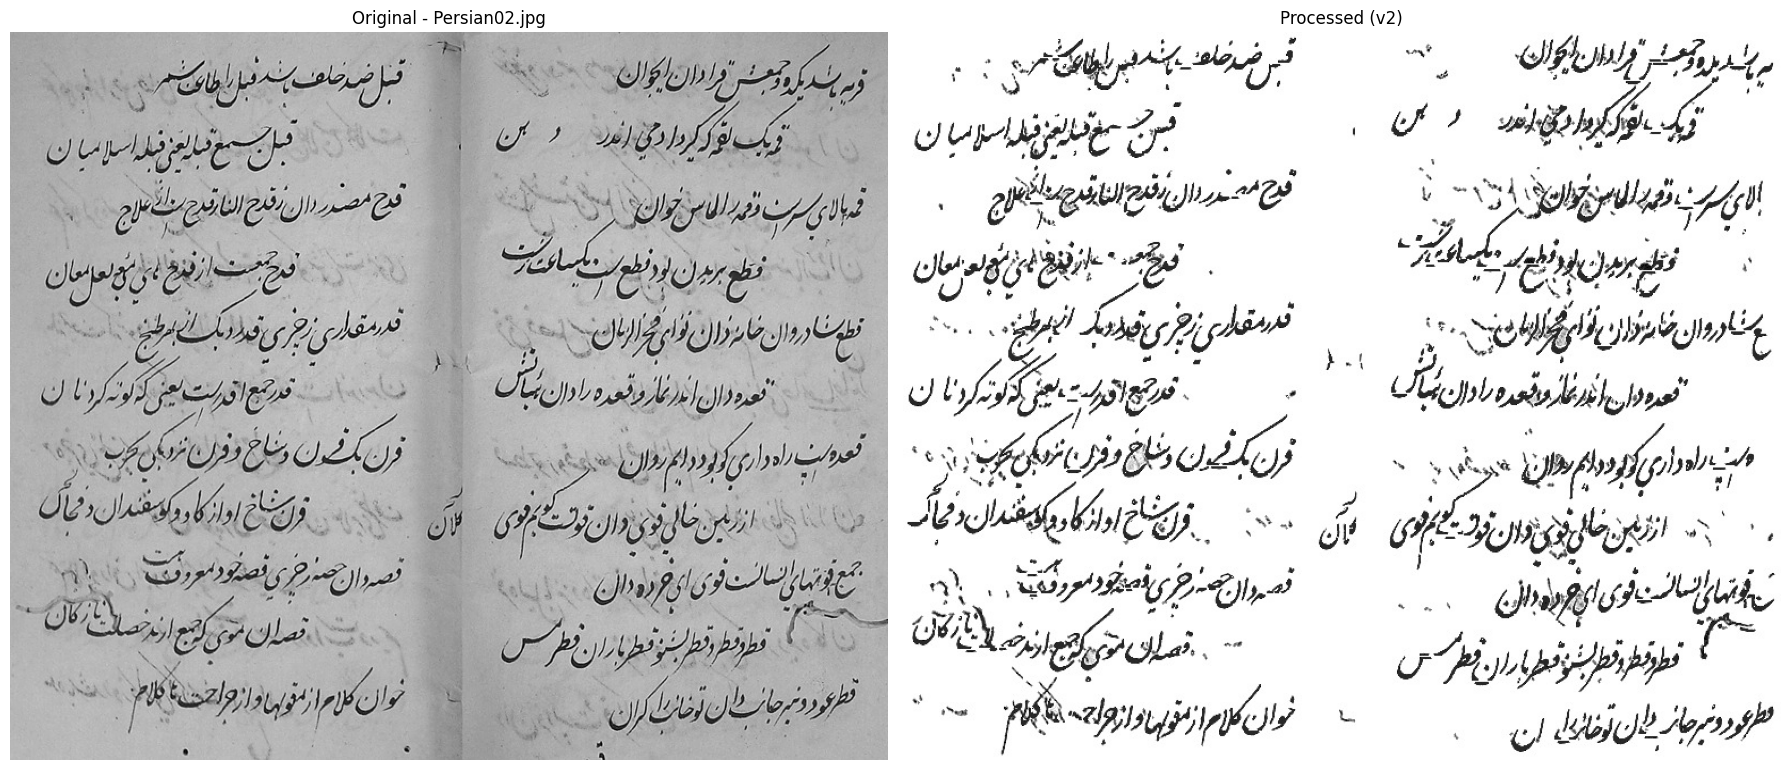

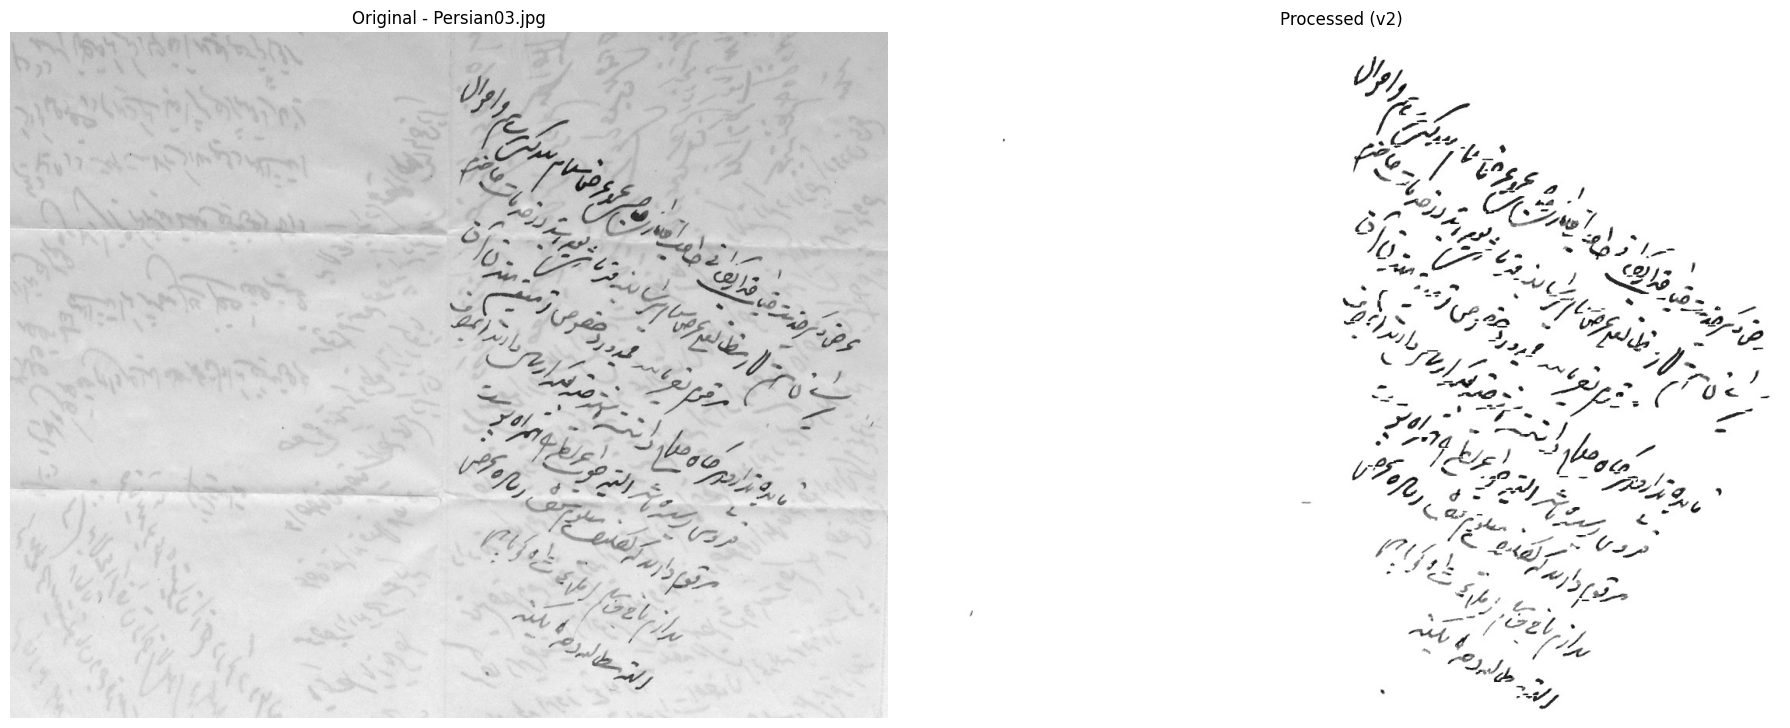

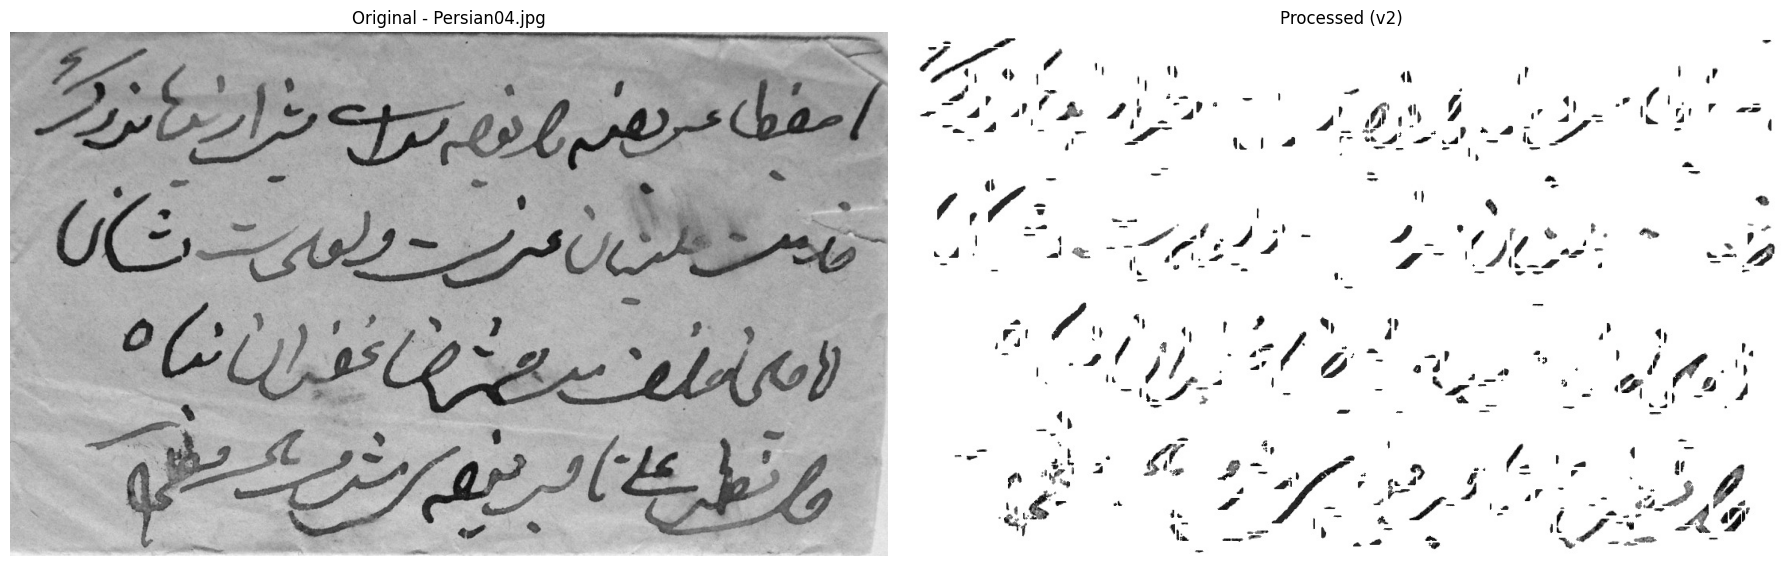

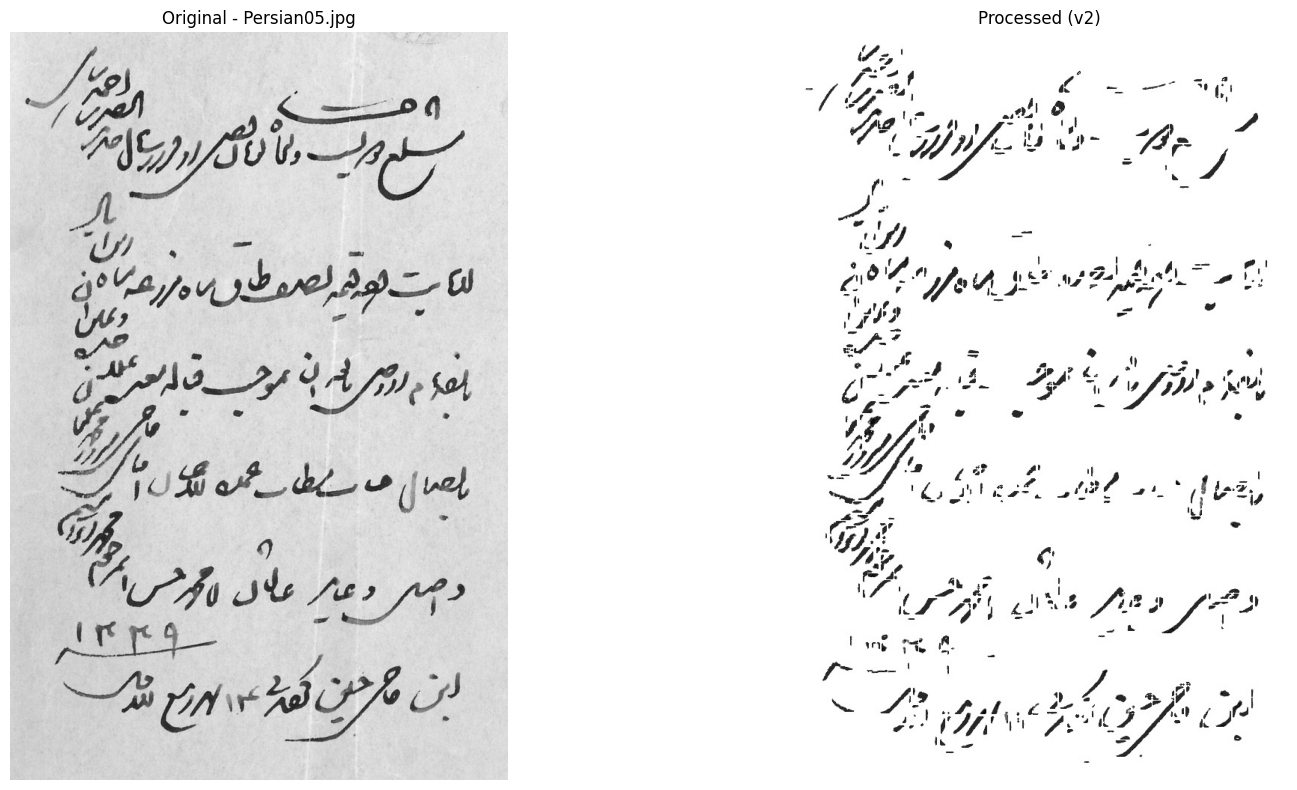

In [12]:
N_SHOW = 5
for fname in files_list[:N_SHOW]:
	orig = cv2.imread(os.path.join(INPUT_DIR, fname), cv2.IMREAD_GRAYSCALE)
	rest = cv2.imread(os.path.join(OUTPUT_DIR, os.path.splitext(fname)[0] + ".jpg"), cv2.IMREAD_GRAYSCALE)
	fig, axes = plt.subplots(1, 2, figsize=(18, 8))
	axes[0].imshow(orig, cmap="gray"); axes[0].set_title(f"Original - {fname}"); axes[0].axis("off")
	if rest is not None:
		axes[1].imshow(rest, cmap="gray")
	axes[1].set_title("Processed (v2)"); axes[1].axis("off")
	plt.tight_layout()
	plt.show()
